# Retrofit Trade-offs: AI-IoT Overlays on Legacy Buildings
AI for Sustainability

Pipeline: load data -> EDA -> baseline ML model (business-as-usual energy) -> simulate AI-IoT overlay savings (cited assumptions) -> payback, NPV, tCO2 -> trade-off plot -> Monte Carlo -> tornado sensitivity -> age-assumption test -> retrofit-first ranking -> regional comparison.

Dataset: Building Data Genome Project 2 (Miller et al., 2020, Scientific Data). Run all cells top to bottom (Colab: Runtime > Run all). The electricity file is ~175 MB, so the first load takes a minute; later runs use the cached copy.

## 1. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': 0.3})
RNG = np.random.default_rng(42)

# --- Choices you can change ---
TYPES = ['Office', 'Education', 'Public services', 'Lodging/residential']   # building types to study (types with no data are skipped)
N_PER_GROUP = 10                  # buildings per (type, legacy/newer) group
LEGACY_BEFORE = 1990              # 'legacy' = built before this year

## 2. Load data (cached)
Files are downloaded once from the project's GitHub repo (Git LFS, hence the `media.githubusercontent.com` link) and saved to disk. Later runs read the saved copy. On Colab the local folder is wiped when the runtime resets; set `USE_DRIVE = True` to keep the cache in your Google Drive instead.

In [2]:
import os, urllib.request
USE_DRIVE = False          # True = cache in Google Drive (survives Colab runtime resets)

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/bdg2_data'
else:
    DATA_DIR = 'bdg2_data'
os.makedirs(DATA_DIR, exist_ok=True)

BASE = "https://media.githubusercontent.com/media/buds-lab/building-data-genome-project-2/master/data/"
FILES = {'electricity_cleaned.csv': 'meters/cleaned/electricity_cleaned.csv',
         'metadata.csv': 'metadata/metadata.csv',
         'weather.csv': 'weather/weather.csv'}

def fetch(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        print(f'Downloading {name} ...')
        urllib.request.urlretrieve(BASE + FILES[name], path + '.part')
        os.replace(path + '.part', path)
    else:
        print(f'Using cached {name}')
    return path

elec = pd.read_csv(fetch('electricity_cleaned.csv'), parse_dates=['timestamp'])
meta = pd.read_csv(fetch('metadata.csv'))
weather = pd.read_csv(fetch('weather.csv'), parse_dates=['timestamp'])
print(elec.shape, meta.shape, weather.shape)

Using cached electricity_cleaned.csv
Using cached metadata.csv
Using cached weather.csv
(17544, 1579) (1636, 32) (331166, 10)


## 3. Select buildings
Office and education buildings with known year built, floor area, and mostly complete electricity data.

In [3]:
ok_cols = set(elec.columns)
m = meta[meta.primaryspaceusage.isin(TYPES) & meta.yearbuilt.notna() & meta.sqm.notna()
         & meta.building_id.isin(ok_cols)].copy()
m['legacy'] = m.yearbuilt < LEGACY_BEFORE
m['completeness'] = m.building_id.map(lambda b: elec[b].notna().mean())
m = m[m.completeness > 0.9]
# Drop implausible floor-area / meter combinations (electricity EUI outside 15-500 kWh/m2/yr)
m['eui'] = m.apply(lambda r: elec[r.building_id].mean() * 8760 / r.sqm, axis=1)
n_before = len(m)
m = m[m.eui.between(15, 500)]
print(f'Removed {n_before - len(m)} buildings with implausible EUI')

# Stratified sample: equal numbers of legacy and newer buildings per type (if available)
groups = [m[(m.primaryspaceusage == t) & (m.legacy == lg)] for t in TYPES for lg in (True, False)]
sel = pd.concat([g.sample(min(N_PER_GROUP, len(g)), random_state=42) for g in groups])
sel = sel[['building_id', 'site_id', 'primaryspaceusage', 'sqm', 'yearbuilt', 'legacy']].reset_index(drop=True)
print('Available:', m.groupby(['primaryspaceusage', 'legacy']).size().to_dict())
print(sel.groupby(['primaryspaceusage', 'legacy']).size().unstack(fill_value=0))
sel.head()

Removed 25 buildings with implausible EUI
Available: {('Education', False): 45, ('Education', True): 236, ('Lodging/residential', False): 13, ('Lodging/residential', True): 41, ('Office', False): 10, ('Office', True): 45, ('Public services', False): 10, ('Public services', True): 35}
legacy               False  True 
primaryspaceusage                
Education               10     10
Lodging/residential     10     10
Office                  10     10
Public services         10     10


,building_id,site_id,primaryspaceusage,sqm,yearbuilt,legacy
0,Cockatoo_office_Georgia,Cockatoo,Office,14672.4,1932.0,True
1,Lamb_office_Vasiliki,Lamb,Office,25087.0,1976.0,True
2,Lamb_office_Maggie,Lamb,Office,1134.0,1976.0,True
3,Cockatoo_office_Delores,Cockatoo,Office,7861.0,1963.0,True
4,Cockatoo_office_Paige,Cockatoo,Office,12151.2,1933.0,True


## 4. Build the modelling table (long format + weather + time features)

In [4]:
parts = []
for _, r in sel.iterrows():
    d = elec[['timestamp', r.building_id]].rename(columns={r.building_id: 'kwh'})
    d['building_id'], d['site_id'] = r.building_id, r.site_id
    parts.append(d)
df = pd.concat(parts, ignore_index=True)

w = (weather.drop_duplicates(['site_id', 'timestamp'])
            [['site_id', 'timestamp', 'airTemperature', 'dewTemperature', 'windSpeed', 'cloudCoverage']])
df = df.merge(w, on=['site_id', 'timestamp'], how='left')
df = df.sort_values(['building_id', 'timestamp'])
df[['airTemperature', 'dewTemperature', 'windSpeed', 'cloudCoverage']] = (
    df.groupby('building_id')[['airTemperature', 'dewTemperature', 'windSpeed', 'cloudCoverage']].ffill())

# Data quality: treat zero/negative readings and extreme spikes as missing
df.loc[df.kwh <= 0, 'kwh'] = np.nan
p99 = df.groupby('building_id').kwh.transform(lambda x: x.quantile(0.99))
df.loc[df.kwh > 3 * p99, 'kwh'] = np.nan

df['hour'] = df.timestamp.dt.hour
df['dow'] = df.timestamp.dt.dayofweek
df['month'] = df.timestamp.dt.month
df['weekend'] = (df.dow >= 5).astype(int)
df['year'] = df.timestamp.dt.year
df['week_id'] = (df.timestamp - df.timestamp.min()).dt.days // 7
df = df.merge(sel[['building_id', 'primaryspaceusage', 'sqm', 'yearbuilt', 'legacy']], on='building_id')
print(df.shape); df.head()

(1403520, 18)


,timestamp,kwh,building_id,site_id,airTemperature,dewTemperature,windSpeed,cloudCoverage,hour,dow,month,weekend,year,week_id,primaryspaceusage,sqm,yearbuilt,legacy
0,2016-01-01 00:00:00,48.00,Bear_education_Clint,Bear,4.4,-2.2,0.0,0.0,0,4,1,0,2016,0,Education,3836.6,1959.0,True
1,2016-01-01 01:00:00,48.00,Bear_education_Clint,Bear,4.4,-4.4,2.1,0.0,1,4,1,0,2016,0,Education,3836.6,1959.0,True
2,2016-01-01 02:00:00,48.00,Bear_education_Clint,Bear,4.4,-6.7,2.1,0.0,2,4,1,0,2016,0,Education,3836.6,1959.0,True
3,2016-01-01 03:00:00,46.75,Bear_education_Clint,Bear,4.4,-7.8,2.6,0.0,3,4,1,0,2016,0,Education,3836.6,1959.0,True
4,2016-01-01 04:00:00,48.25,Bear_education_Clint,Bear,5.0,-9.4,0.0,0.0,4,4,1,0,2016,0,Education,3836.6,1959.0,True


## 5. Exploratory analysis

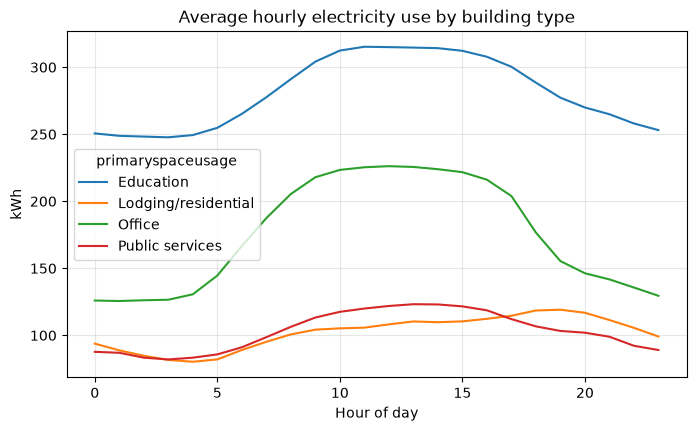

In [5]:
# (a) Average daily profile by building type
prof = df.groupby(['primaryspaceusage', 'hour']).kwh.mean().unstack(0)
prof.plot(title='Average hourly electricity use by building type', xlabel='Hour of day', ylabel='kWh')
plt.show()

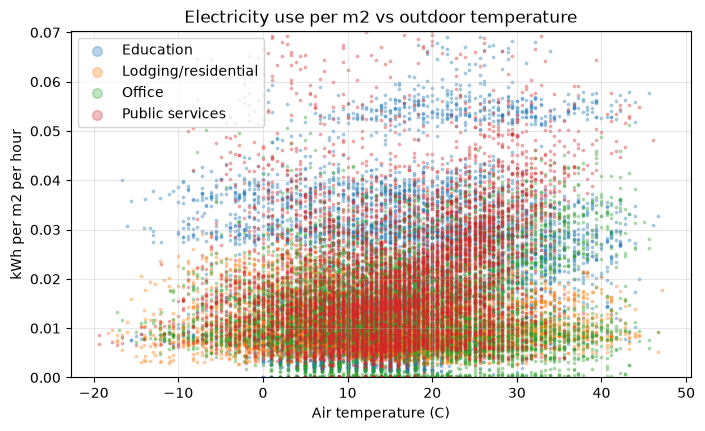

In [6]:
# (b) Consumption per m2 vs outdoor temperature
s_ = df.dropna(subset=['kwh', 'airTemperature']).sample(30000, random_state=1)
s_['kwh_m2'] = s_.kwh / s_.sqm
for t, g_ in s_.groupby('primaryspaceusage'):
    plt.scatter(g_.airTemperature, g_.kwh_m2, s=3, alpha=0.3, label=t)
plt.ylim(0, s_.kwh_m2.quantile(0.995))
plt.title('Electricity use per m2 vs outdoor temperature'); plt.xlabel('Air temperature (C)'); plt.ylabel('kWh per m2 per hour')
plt.legend(markerscale=4); plt.show()

                                    count  median
use                 age_group                    
Education           Legacy (<1990)     10   111.4
                    Newer (>=1990)     10   210.9
Lodging/residential Legacy (<1990)     10    81.7
                    Newer (>=1990)     10   111.7
Office              Legacy (<1990)     10    85.5
                    Newer (>=1990)     10   167.1
Public services     Legacy (<1990)     10   153.0
                    Newer (>=1990)     10   159.4


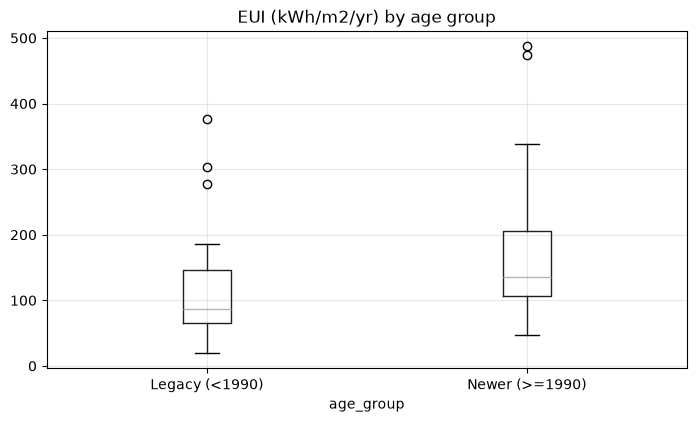

In [7]:
# (c) Energy use intensity (kWh/m2/year) by building age group
eui = df.groupby('building_id').agg(kwh=('kwh', 'mean'), sqm=('sqm', 'first'),
                                    yr=('yearbuilt', 'first'), use=('primaryspaceusage', 'first'))
eui['EUI'] = eui.kwh * 8760 / eui.sqm
eui['age_group'] = np.where(eui.yr < LEGACY_BEFORE, f'Legacy (<{LEGACY_BEFORE})', f'Newer (>={LEGACY_BEFORE})')
print(eui.groupby(['use', 'age_group']).EUI.agg(['count', 'median']).round(1))
eui.boxplot(column='EUI', by='age_group'); plt.suptitle(''); plt.title('EUI (kWh/m2/yr) by age group')
plt.show()

## 6. Baseline ML model (business-as-usual energy)
One XGBoost model per building. **Validation:** every 5th week (across 2016 and 2017) is held out for testing, the rest is used for training. Accuracy is judged with **CV(RMSE)** and **R2**; ASHRAE Guideline 14 accepts hourly CV(RMSE) up to about 30%, so buildings above that are dropped from the retrofit analysis (their baseline is not trustworthy). The final BAU profile for 2017 comes from a model trained on all valid data.

In [8]:
FEATS = ['hour', 'dow', 'month', 'weekend', 'airTemperature', 'dewTemperature', 'windSpeed', 'cloudCoverage']
def make_model():
    return XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8, n_jobs=-1, random_state=42)

results, bau_pred, cv_pred = [], {}, {}
for b, g in df.groupby('building_id'):
    valid = g.kwh.notna()
    is_test = (g.week_id % 5 == 0)
    tr, te = g[valid & ~is_test], g[valid & is_test]
    m_cv = make_model().fit(tr[FEATS], tr.kwh)
    cv_pred[b] = pd.Series(m_cv.predict(g[is_test][FEATS]), index=g[is_test].index)
    p = m_cv.predict(te[FEATS])
    rmse = mean_squared_error(te.kwh, p) ** 0.5
    results.append({'building_id': b, 'RMSE': rmse, 'CVRMSE_%': 100 * rmse / te.kwh.mean(), 'R2': r2_score(te.kwh, p)})
    m_full = make_model().fit(g[valid][FEATS], g[valid].kwh)           # final BAU model
    g17 = g[g.year == 2017]
    bau_pred[b] = pd.Series(m_full.predict(g17[FEATS]), index=g17.index)

perf = pd.DataFrame(results)
print('All selected buildings:'); print(perf[['CVRMSE_%', 'R2']].describe().round(2))

good = perf[perf['CVRMSE_%'] < 30].building_id
sel_ok = sel[sel.building_id.isin(good)].reset_index(drop=True)
print(f"\nKept {len(sel_ok)} of {len(sel)} buildings with CV(RMSE) < 30%")
print(sel_ok.groupby(['primaryspaceusage', 'legacy']).size().unstack(fill_value=0))

All selected buildings:
       CVRMSE_%     R2
count     80.00  80.00
mean      24.31   0.59
std       21.01   0.22
min        3.59  -0.02
25%       11.24   0.46
50%       17.93   0.64
75%       27.92   0.77
max      118.04   0.91

Kept 62 of 80 buildings with CV(RMSE) < 30%
legacy               False  True 
primaryspaceusage                
Education                7      6
Lodging/residential      9     10
Office                   7      6
Public services          9      8


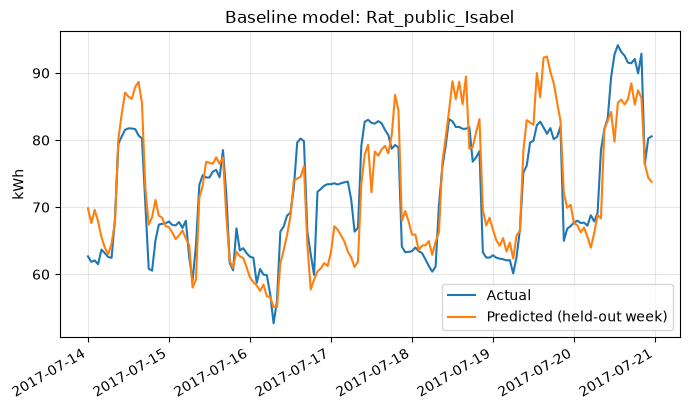

In [9]:
# Predicted vs actual on a held-out week of 2017 for a median-accuracy building
pk = perf[perf.building_id.isin(good)].sort_values('CVRMSE_%')
b = pk.building_id.iloc[len(pk) // 2]
g = df[df.building_id == b]
wks = sorted(g[(g.year == 2017) & (g.week_id % 5 == 0)].week_id.unique())
wk = g[g.week_id == wks[len(wks) // 2]]
plt.plot(wk.timestamp, wk.kwh, label='Actual')
plt.plot(wk.timestamp, cv_pred[b].loc[wk.index], label='Predicted (held-out week)')
plt.title(f'Baseline model: {b}'); plt.ylabel('kWh'); plt.legend(); plt.gcf().autofmt_xdate(); plt.show()

## 7. Simulate the AI-IoT overlay
Business-as-usual (BAU) = the model's predicted 2017 consumption. The overlay itself is **simulated** with savings percentages taken from published studies (sources in the comments below and in the references at the end). The savings are literature-based assumptions applied to our buildings, not measured results.

| Assumption | Value (min / most likely / max) | Source |
|---|---|---|
| HVAC control savings (of HVAC load) | 5% / 13% / 30% | Field demonstrations of MPC/RL in commercial buildings: 13% weighted-average cost savings (Khabbazi et al., 2025), used here as a proxy for energy savings; a field evaluation of a model-predictive HVAC system found 0-9%; controls issues waste 10-30% of energy (PNNL 2020, cited by LBNL) |
| Occupancy lighting savings (of lighting load) | 10% / 24% / 38% | Meta-analysis of 240 estimates: 24% for occupancy control, 38% for multiple strategies (Williams et al., 2012) |
| Fault detection savings (of total) | 5% / 8% / 16% | Commissioning meta-analysis: 16% median whole-building savings in existing buildings, 13% in new buildings (Mills, 2011). Commissioning is broader than AI fault detection, so 16% is treated as an upper bound; our lower most-likely value also reflects overlap with HVAC control |
| End-use shares, Office | HVAC 45%, lighting 20% | India commercial buildings: HVAC 40-55%, lighting about 20-23% (BEE data cited in TERI retrofit guidelines) |
| End-use shares, other types | HVAC 40%, lighting 20-25% | Generic assumption, tested in the sensitivity analysis |
| Older buildings save more than newer | Legacy: 18% / 30% / 10%; Newer: 8% / 20% / 6% (HVAC / lighting / FDD) | **Our assumption**, inside the cited ranges. Support: HVAC optimisation adds little where best-practice sequences already exist; commissioning saves 16% (existing) vs 13% (new). Tested with `AGE_DEPENDENT` on and off in section 12 |

In [10]:
# End-use shares of whole-building electricity (see table above)
SHARES = {'Office':    {'hvac': 0.45, 'light': 0.20},
          'Education': {'hvac': 0.40, 'light': 0.25}}
SHARES_DEFAULT = {'hvac': 0.40, 'light': 0.20}          # other building types (assumption)
def shares_for(use): return SHARES.get(use, SHARES_DEFAULT)

# Savings ranges (min, most likely, max) - sources in the table above
SAV_RANGE = {'hvac': (0.05, 0.13, 0.30), 'light': (0.10, 0.24, 0.38), 'fdd': (0.05, 0.08, 0.16)}
S = {k: v[1] for k, v in SAV_RANGE.items()}             # base case = most likely values
AGE_DEPENDENT = True                                    # our assumption: older buildings have more savings potential
S_LEGACY = {'hvac': 0.18, 'light': 0.30, 'fdd': 0.10}
S_NEWER  = {'hvac': 0.08, 'light': 0.20, 'fdd': 0.06}

def savings_for(legacy):
    if not AGE_DEPENDENT: return S
    return S_LEGACY if legacy else S_NEWER

def simulate(bau, use, legacy):
    sv, sh = savings_for(legacy), shares_for(use)
    hvac, light = bau * sh['hvac'], bau * sh['light']
    other = bau - hvac - light
    saved = {'Smart HVAC': hvac * sv['hvac'],
             'Occupancy lighting': light * sv['light'],
             'Fault detection': bau * sv['fdd']}
    remaining = hvac * (1 - sv['hvac']) + light * (1 - sv['light']) + other
    saved['Combined'] = bau - remaining * (1 - sv['fdd'])      # multiplicative, not additive
    return saved

bau_kwh = {b: p.sum() for b, p in bau_pred.items()}
print('Example (first building):', {k: round(v) for k, v in simulate(bau_kwh[sel_ok.building_id[0]], sel_ok.primaryspaceusage[0], sel_ok.legacy[0]).items()})

Example (first building): {'Smart HVAC': 171503, 'Occupancy lighting': 127039, 'Fault detection': 211732, 'Combined': 480419}


**BAU calibration check.** The model's 2017 total should match the metered 2017 total. `bias_valid_hours` compares them on hours with valid readings; `BAU_vs_metered_annualised` compares the full-year BAU with the metered average scaled to a full year, so it also shows the effect of filling removed or missing readings.

       bias_valid_hours_%  BAU_vs_metered_annualised_%
count               62.00                        62.00
mean                 1.41                         1.42
std                  2.12                         2.16
min                 -3.85                        -3.85
25%                  0.05                         0.05
50%                  1.17                         1.18
75%                  2.22                         2.27
max                  7.90                         7.90
Kept buildings with annualised BAU within +/-10% of metered: 100%


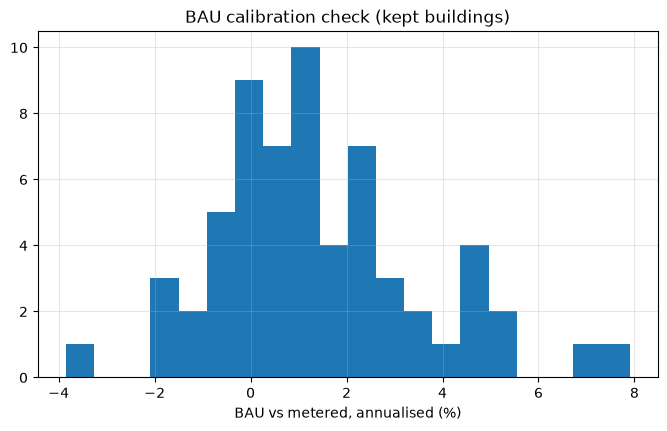

In [11]:
cal = []
for _b, _g in df[df.year == 2017].groupby('building_id'):
    _valid = _g.kwh.notna()
    _pred = bau_pred[_b]
    cal.append({'building_id': _b,
                'bias_valid_hours_%': 100 * (_pred[_valid].sum() / _g.kwh[_valid].sum() - 1),
                'BAU_vs_metered_annualised_%': 100 * (_pred.sum() / (_g.kwh[_valid].mean() * len(_g)) - 1)})
cal = pd.DataFrame(cal).merge(sel_ok[['building_id']], on='building_id')
print(cal[['bias_valid_hours_%', 'BAU_vs_metered_annualised_%']].describe().round(2))
print(f"Kept buildings with annualised BAU within +/-10% of metered: {(cal['BAU_vs_metered_annualised_%'].abs() <= 10).mean():.0%}")
cal['BAU_vs_metered_annualised_%'].hist(bins=20); plt.xlabel('BAU vs metered, annualised (%)'); plt.title('BAU calibration check (kept buildings)'); plt.show()

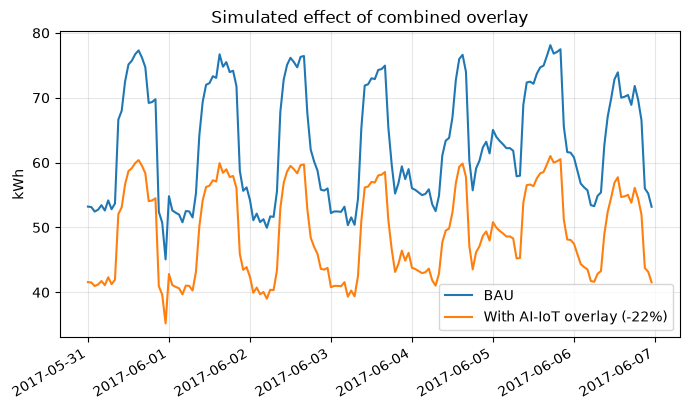

In [12]:
# Before/after for one week: combined package
bsel = b
use = sel_ok.set_index('building_id').loc[bsel, 'primaryspaceusage']
frac = simulate(bau_kwh[bsel], use, sel_ok.set_index('building_id').loc[bsel, 'legacy'])['Combined'] / bau_kwh[bsel]
wk17 = g[g.year == 2017].iloc[24 * 150: 24 * 157]
base = bau_pred[bsel].loc[wk17.index]
plt.plot(wk17.timestamp, base, label='BAU')
plt.plot(wk17.timestamp, base * (1 - frac), label=f'With AI-IoT overlay (-{frac:.0%})')
plt.title('Simulated effect of combined overlay'); plt.ylabel('kWh'); plt.legend(); plt.gcf().autofmt_xdate(); plt.show()

## 8. Economics and carbon
Sourced inputs: electricity price range, grid emission factor. **Capex and opex are still assumptions**, because published per-m2 costs for AI-IoT overlays vary widely; they are tested explicitly in the capex sensitivity and the tornado chart. (For scale, LBNL reports a median cost of about $3/m2 for one-time commissioning in existing buildings; a full sensor-and-software overlay costs more.)

| Input | Value | Source |
|---|---|---|
| Electricity tariff | Rs 8/kWh (range Rs 6-11) | State commercial tariffs in 2025-26 are around Rs 6-8/kWh in states such as Punjab and Himachal Pradesh and higher in metros; CEA publishes the state-wise Electricity Tariff & Duty compilation |
| Grid emission factor, India | 0.710 kg CO2/kWh (range 0.65-0.79) | CEA CO2 Baseline Database: 0.710 t/MWh for FY2024-25 (v21, provisional), 0.727 for FY2023-24 (v20), 0.79 for FY2019-20. Check the FY2024-25 figure in the CEA PDF before quoting |
| System life / discount rate | 10 years / 10% | Assumption |
| Capex, opex | Capex = fixed cost per building + cost per m2 (combined: about Rs 405,000 + Rs 360/m2); opex about Rs 22.5/m2/yr (combined) | Assumption (see above). A fixed part makes small buildings cost more per m2 |

In [13]:
TARIFF = 8.0          # Rs per kWh (commercial); range below
TARIFF_RANGE = (6.0, 8.0, 11.0)
EF = 0.710            # kg CO2 per kWh (CEA v21, FY2024-25 provisional)
EF_RANGE = (0.65, 0.71, 0.79)
CAPEX_MULT_RANGE = (0.5, 1.0, 2.0)   # capex is the least certain input
LIFE, DISC = 10, 0.10 # years, discount rate
# Costs (ASSUMPTIONS): capex = fixed cost per building + cost per m2; opex = running cost per m2 per year
CAPEX_M2    = {'Smart HVAC': 200, 'Occupancy lighting': 150, 'Fault detection': 50}                 # Rs per m2
CAPEX_FIXED = {'Smart HVAC': 200_000, 'Occupancy lighting': 100_000, 'Fault detection': 150_000}   # Rs per building (gateway, integration, setup)
OPEX_M2     = {'Smart HVAC': 10, 'Occupancy lighting': 5, 'Fault detection': 10}                    # Rs per m2 per year (subscription, maintenance)
for d_ in (CAPEX_M2, CAPEX_FIXED, OPEX_M2):
    d_['Combined'] = 0.9 * sum(d_.values())        # shared sensors/gateway -> 10% discount
def capex_for(scen, sqm): return CAPEX_FIXED[scen] + CAPEX_M2[scen] * sqm
def opex_for(scen, sqm): return OPEX_M2[scen] * sqm

annuity = sum(1 / (1 + DISC) ** t for t in range(1, LIFE + 1))
rows = []
for _, r in sel_ok.iterrows():
    bau = bau_kwh[r.building_id]
    for scen, kwh in simulate(bau, r.primaryspaceusage, r.legacy).items():
        capex, opex = capex_for(scen, r.sqm), opex_for(scen, r.sqm)
        net_annual = kwh * TARIFF - opex
        tco2 = kwh * EF / 1000
        rows.append({'building_id': r.building_id, 'type': r.primaryspaceusage, 'legacy': r.legacy,
                     'sqm': r.sqm, 'scenario': scen, 'BAU_kWh': bau, 'saved_kWh': kwh,
                     'saving_%': 100 * kwh / bau, 'capex_Rs': capex, 'opex_Rs': opex,
                     'payback_yrs': capex / net_annual if net_annual > 0 else np.inf,
                     'NPV_Rs': -capex + net_annual * annuity,
                     'tCO2_avoided_yr': tco2, 'CO2_reduction_%': 100 * kwh / bau,
                     'Rs_per_tCO2': (capex - net_annual * LIFE) / (tco2 * LIFE) if tco2 > 0 else np.nan})
res = pd.DataFrame(rows)
res.groupby('scenario')[['saving_%', 'payback_yrs', 'tCO2_avoided_yr', 'Rs_per_tCO2']].median().round(2)

,saving_%,payback_yrs,tCO2_avoided_yr,Rs_per_tCO2
scenario,,,,
Combined,13.71,3.23,101.680000,-6537.439941
Fault detection,6.00,1.22,46.279999,-8441.469727
Occupancy lighting,5.00,4.00,31.430000,-6044.319824
Smart HVAC,3.60,6.00,29.440001,-3657.709961


In [14]:
res[res.scenario == 'Combined'].sort_values('payback_yrs')[
    ['building_id', 'type', 'legacy', 'sqm', 'saved_kWh', 'payback_yrs', 'NPV_Rs', 'tCO2_avoided_yr', 'Rs_per_tCO2']].round(1).head(10)

,building_id,type,legacy,sqm,saved_kWh,payback_yrs,NPV_Rs,tCO2_avoided_yr,Rs_per_tCO2
55,Rat_education_Jena,Education,True,3804.4,3.312442e+05,0.7,13982267.0,235.199997,-10149.099609
99,Fox_education_Claude,Education,False,17957.6,1.171886e+06,0.8,48253456.0,832.000000,-9956.299805
71,Cockatoo_education_Sheryl,Education,True,14927.0,9.485432e+05,0.8,38784680.0,673.500000,-9910.799805
87,Cockatoo_education_Tyler,Education,False,19928.2,9.169620e+05,1.1,34740396.0,651.000000,-9414.700195
119,Rat_public_Isabel,Public services,True,1540.0,1.038627e+05,1.2,3933222.0,73.699997,-9496.700195
167,Rat_public_Yessenia,Public services,False,2043.9,1.230453e+05,1.2,4625102.5,87.400002,-9435.400391
79,Cockatoo_education_Janet,Education,False,29946.4,1.197007e+06,1.3,43514840.0,849.900024,-9158.599609
91,Fox_education_Yolande,Education,False,16681.6,6.273535e+05,1.4,22121872.0,445.399994,-8985.799805
195,Cockatoo_lodging_Elvia,Lodging/residential,True,13962.8,4.971512e+05,1.5,17076230.0,353.000000,-8838.799805
151,Fox_public_Denny,Public services,False,4058.1,1.595702e+05,1.6,5416961.0,113.300003,-8814.700195


## 9. Trade-off: payback vs carbon reduction
Payback is driven by two things: how much energy a building uses per m2 (high-intensity buildings pay back faster) and, with `AGE_DEPENDENT = True`, the assumption that older buildings have more savings potential. Set `AGE_DEPENDENT = False` and re-run to see how much of the result comes from that assumption alone.

The first plot shows absolute carbon avoided per 1000 m2. Because both axes depend mainly on saved kWh per m2, the points fall close to one curve. The second plot uses the percentage reduction of each building's own consumption, which depends on end-use shares and the age assumption, so it shows a different side of the trade-off. This percentage takes only a few distinct values, one per building type and age group, because it is set by the assumed shares and savings: it is an assumption output, not something learned from the data. Only payback and absolute tCO2 vary with each building's own energy use and size.

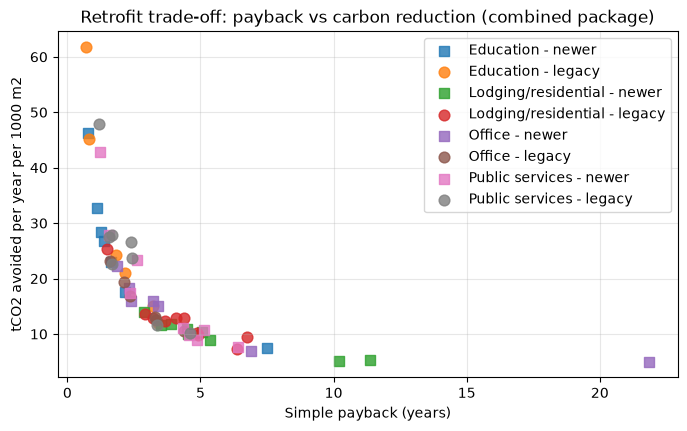

In [15]:
c = res[res.scenario == 'Combined'].copy()
c['tCO2_per_1000m2'] = c.tCO2_avoided_yr / c.sqm * 1000
fig, ax = plt.subplots()
for (t, lg), g in c.groupby(['type', 'legacy']):
    ax.scatter(g.payback_yrs, g.tCO2_per_1000m2, s=60, alpha=0.8,
               marker='o' if lg else 's', label=f"{t} - {'legacy' if lg else 'newer'}")
ax.set_xlabel('Simple payback (years)'); ax.set_ylabel('tCO2 avoided per year per 1000 m2')
ax.set_title('Retrofit trade-off: payback vs carbon reduction (combined package)'); ax.legend()
plt.show()

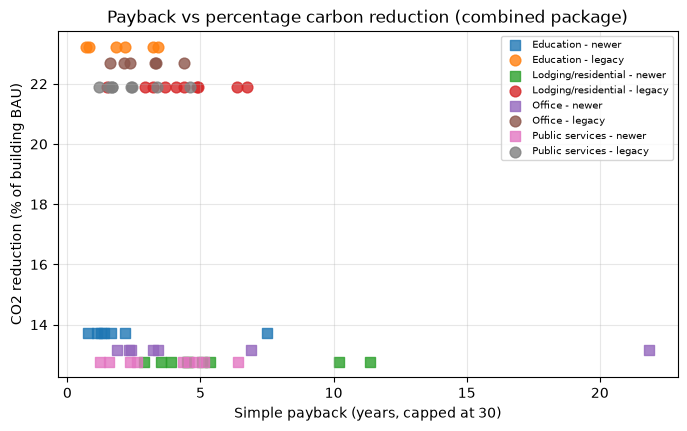

In [16]:
# Percentage CO2 reduction vs payback: depends on end-use shares and the age assumption, so it is not a rescaled copy of the plot above
fig, ax = plt.subplots()
for (t, lg), g_ in c.groupby(['type', 'legacy']):
    ax.scatter(g_.payback_yrs.clip(upper=30), g_['CO2_reduction_%'], s=60, alpha=0.8,
               marker='o' if lg else 's', label=f"{t} - {'legacy' if lg else 'newer'}")
ax.set_xlabel('Simple payback (years, capped at 30)'); ax.set_ylabel('CO2 reduction (% of building BAU)')
ax.set_title('Payback vs percentage carbon reduction (combined package)'); ax.legend(fontsize=7)
plt.show()

In [17]:
c.groupby(['type', 'legacy'])[['payback_yrs', 'tCO2_per_1000m2', 'NPV_Rs']].median().round(2)

payback_yrs  tCO2_per_1000m2        NPV_Rs
type                legacy                                            
Education           False          1.38            26.70  2.212187e+07
                    True           2.00            22.64  4.980248e+06
Lodging/residential False          4.55            10.36  7.633402e+05
                    True           4.22            12.62  6.545119e+05
Office              False          3.20            15.97  1.292918e+06
                    True           2.84            14.98  5.022728e+06
Public services     False          4.32            11.04  1.412731e+06
                    True           2.03            25.20  4.082782e+06

## 10. Monte Carlo simulation
Samples the uncertain assumptions from triangular distributions (min, most likely, max) using the cited ranges, and reports the spread of the median payback across the selected buildings. Each run draws one value per input and applies it to all buildings (age-dependent scaling is kept if `AGE_DEPENDENT` is on).

Median payback across portfolio: P5=1.8, P50=3.1, P95=5.7 years
Probability median payback <= 5 years: 90%


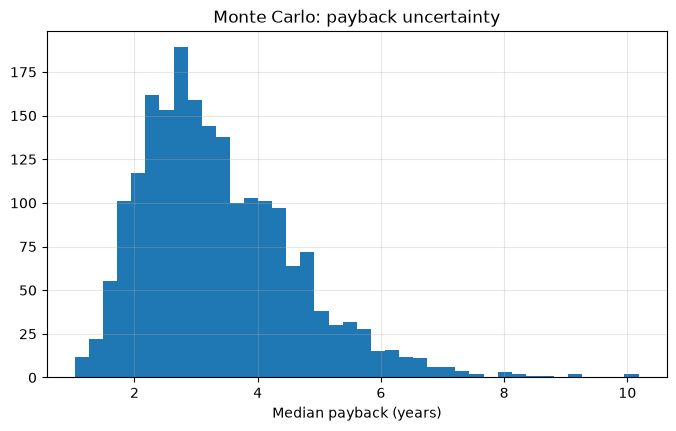

In [18]:
N = 2000
combined_rows = res[res.scenario == 'Combined']
bau_arr = combined_rows.BAU_kWh.values; sqm_arr = combined_rows.sqm.values
use_arr = combined_rows.type.values; leg_arr = combined_rows.legacy.values
capex_arr = np.array([capex_for('Combined', s) for s in sqm_arr]); opex_arr = np.array([opex_for('Combined', s) for s in sqm_arr])
hv_sh = np.array([shares_for(u)['hvac'] for u in use_arr]); li_sh = np.array([shares_for(u)['light'] for u in use_arr])

med_pay = []
for _ in range(N):
    tariff = RNG.triangular(*TARIFF_RANGE)
    s_h, s_l, s_f = (RNG.triangular(*SAV_RANGE['hvac']), RNG.triangular(*SAV_RANGE['light']), RNG.triangular(*SAV_RANGE['fdd']))
    if AGE_DEPENDENT:   # scale draws by age group relative to the base case
        s_h = np.minimum(0.9, s_h * np.where(leg_arr, S_LEGACY['hvac'], S_NEWER['hvac']) / S['hvac'])
        s_l = np.minimum(0.9, s_l * np.where(leg_arr, S_LEGACY['light'], S_NEWER['light']) / S['light'])
        s_f = np.minimum(0.9, s_f * np.where(leg_arr, S_LEGACY['fdd'], S_NEWER['fdd']) / S['fdd'])
    capex = capex_arr * RNG.triangular(*CAPEX_MULT_RANGE)
    remaining = bau_arr * (hv_sh * (1 - s_h) + li_sh * (1 - s_l) + (1 - hv_sh - li_sh))
    saved = bau_arr - remaining * (1 - s_f)
    net = saved * tariff - opex_arr * RNG.triangular(0.5, 1.0, 2.0)
    pay = np.where(net > 0, capex / net, np.inf)
    med_pay.append(np.median(pay))

med_pay = np.array(med_pay)
print(f"Median payback across portfolio: P5={np.percentile(med_pay,5):.1f}, P50={np.percentile(med_pay,50):.1f}, P95={np.percentile(med_pay,95):.1f} years")
print(f"Probability median payback <= 5 years: {(med_pay <= 5).mean():.0%}")
plt.hist(med_pay[np.isfinite(med_pay)], bins=40); plt.xlabel('Median payback (years)'); plt.title('Monte Carlo: payback uncertainty'); plt.show()

In [19]:
# Capex sensitivity: our capex numbers are placeholders, so check how payback changes if real costs are higher
cr = res[res.scenario == 'Combined']
rows = []
for mult in [1, 2, 3, 4]:
    capex = cr.capex_Rs * mult
    net = cr.saved_kWh * TARIFF - cr.opex_Rs
    pay = np.where(net > 0, capex / net, np.inf)
    rows.append({'capex_multiplier': mult, 'median_payback_yrs': np.median(pay),
                 '%_buildings_payback<=5yrs': 100 * (pay <= 5).mean()})
pd.DataFrame(rows).round(1)

,capex_multiplier,median_payback_yrs,%_buildings_payback<=5yrs
0,1,3.2,82.3
1,2,6.5,41.9
2,3,9.7,21.0
3,4,12.9,9.7


## 11. Reusable portfolio function and sanity check
`run_portfolio()` recomputes the combined-package results for all kept buildings with any assumption changed. The sections below call it with different inputs. The check confirms it reproduces the main results table.

In [20]:
def run_portfolio(tariff=TARIFF, ef=EF, capex_mult=1.0, opex_mult=1.0, age_dependent=None,
                  sav_scale=(1.0, 1.0, 1.0), hvac_shift=0.0, light_shift=0.0):
    age_dependent = AGE_DEPENDENT if age_dependent is None else age_dependent
    out = []
    for _, r in sel_ok.iterrows():
        bau = bau_kwh[r.building_id]
        sh = shares_for(r.primaryspaceusage)
        h = float(np.clip(sh['hvac'] + hvac_shift, 0.05, 0.85))
        l = float(np.clip(sh['light'] + light_shift, 0.02, 0.9 - h))
        base = (S_LEGACY if r.legacy else S_NEWER) if age_dependent else S
        s_h, s_l, s_f = [min(0.9, base[k] * f) for k, f in zip(('hvac', 'light', 'fdd'), sav_scale)]
        remaining = h * (1 - s_h) + l * (1 - s_l) + (1 - h - l)
        saved = bau * (1 - remaining * (1 - s_f))
        capex = capex_for('Combined', r.sqm) * capex_mult
        net = saved * tariff - opex_for('Combined', r.sqm) * opex_mult
        tco2 = saved * ef / 1000
        out.append({'building_id': r.building_id, 'type': r.primaryspaceusage, 'legacy': r.legacy, 'sqm': r.sqm,
                    'BAU_kWh': bau, 'saved_kWh': saved,
                    'payback_yrs': capex / net if net > 0 else np.inf,
                    'NPV_Rs': -capex + net * annuity, 'tCO2_avoided_yr': tco2,
                    'tCO2_per_1000m2': tco2 / r.sqm * 1000,
                    'Rs_per_tCO2': (capex - net * LIFE) / (tco2 * LIFE) if tco2 > 0 else np.nan})
    return pd.DataFrame(out)

check = run_portfolio()
print('Matches main results table:', np.allclose(check.saved_kWh.values, res[res.scenario == 'Combined'].saved_kWh.values),
      '| buildings:', len(check))

Matches main results table: True | buildings: 62


## 12. Tornado-chart sensitivity
Each input is moved from its low to its high value while all others stay at the base case. The bar length shows how much the result swings, so the longest bars are the assumptions that matter most. Payback values are capped at 50 years for plotting. The ranking depends on the ranges chosen: capex has the widest range (0.5x-2x), so it tends to rank first, and the fault-detection savings range is only loosely sourced.

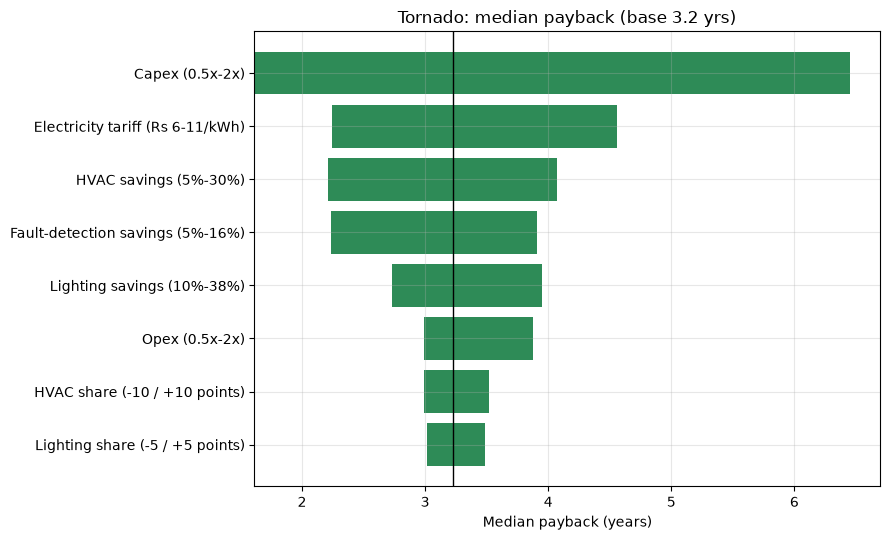

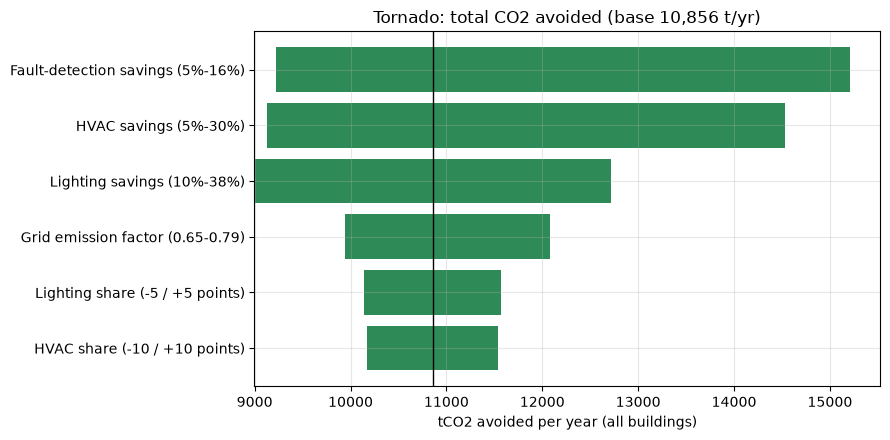

,input,pay_lo,pay_hi,co2_lo,co2_hi
0,Electricity tariff (Rs 6-11/kWh),4.6,2.2,10855.599609,10855.599609
1,HVAC savings (5%-30%),4.1,2.2,9127.900391,14526.799805
2,Lighting savings (10%-38%),4.0,2.7,8997.700195,12713.500000
3,Fault-detection savings (5%-16%),3.9,2.2,9222.000000,15211.799805
4,Capex (0.5x-2x),1.6,6.5,10855.599609,10855.599609
5,Opex (0.5x-2x),3.0,3.9,10855.599609,10855.599609
6,HVAC share (-10 / +10 points),3.5,3.0,10168.400391,11542.799805
7,Lighting share (-5 / +5 points),3.5,3.0,10139.599609,11571.599609
8,Grid emission factor (0.65-0.79),3.2,3.2,9938.200195,12078.700195


In [21]:
def sens_row(label, lo_kw, hi_kw):
    lo, hi = run_portfolio(**lo_kw), run_portfolio(**hi_kw)
    return {'input': label,
            'pay_lo': lo.payback_yrs.median(), 'pay_hi': hi.payback_yrs.median(),
            'co2_lo': lo.tCO2_avoided_yr.sum(), 'co2_hi': hi.tCO2_avoided_yr.sum()}

hv, li, fd = SAV_RANGE['hvac'], SAV_RANGE['light'], SAV_RANGE['fdd']
sens = pd.DataFrame([
    sens_row(f'Electricity tariff (Rs {TARIFF_RANGE[0]:g}-{TARIFF_RANGE[2]:g}/kWh)', dict(tariff=TARIFF_RANGE[0]), dict(tariff=TARIFF_RANGE[2])),
    sens_row(f'HVAC savings ({hv[0]:.0%}-{hv[2]:.0%})', dict(sav_scale=(hv[0] / S['hvac'], 1, 1)), dict(sav_scale=(hv[2] / S['hvac'], 1, 1))),
    sens_row(f'Lighting savings ({li[0]:.0%}-{li[2]:.0%})', dict(sav_scale=(1, li[0] / S['light'], 1)), dict(sav_scale=(1, li[2] / S['light'], 1))),
    sens_row(f'Fault-detection savings ({fd[0]:.0%}-{fd[2]:.0%})', dict(sav_scale=(1, 1, fd[0] / S['fdd'])), dict(sav_scale=(1, 1, fd[2] / S['fdd']))),
    sens_row(f'Capex ({CAPEX_MULT_RANGE[0]:g}x-{CAPEX_MULT_RANGE[2]:g}x)', dict(capex_mult=CAPEX_MULT_RANGE[0]), dict(capex_mult=CAPEX_MULT_RANGE[2])),
    sens_row('Opex (0.5x-2x)', dict(opex_mult=0.5), dict(opex_mult=2.0)),
    sens_row('HVAC share (-10 / +10 points)', dict(hvac_shift=-0.10), dict(hvac_shift=0.10)),
    sens_row('Lighting share (-5 / +5 points)', dict(light_shift=-0.05), dict(light_shift=0.05)),
    sens_row(f'Grid emission factor ({EF_RANGE[0]:g}-{EF_RANGE[2]:g})', dict(ef=EF_RANGE[0]), dict(ef=EF_RANGE[2])),
])
sens['pay_swing'] = (sens[['pay_lo', 'pay_hi']].clip(upper=50).max(axis=1) - sens[['pay_lo', 'pay_hi']].clip(upper=50).min(axis=1))
sens['co2_swing'] = (sens[['co2_lo', 'co2_hi']].max(axis=1) - sens[['co2_lo', 'co2_hi']].min(axis=1))
base_pay, base_co2 = check.payback_yrs.median(), check.tCO2_avoided_yr.sum()

def tornado(df, lo, hi, base, swing, title, xlabel, cap=None):
    d = df[df[swing] > 1e-9].sort_values(swing)
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(d) + 1.5))
    for y, (_, r) in enumerate(d.iterrows()):
        v = [r[lo], r[hi]]
        if cap: v = [min(x, cap) for x in v]
        ax.barh(y, max(v) - min(v), left=min(v), color='#2E8B57')
    ax.axvline(base, color='k', lw=1)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.input); ax.set_xlabel(xlabel); ax.set_title(title)
    plt.tight_layout(); plt.show()

tornado(sens, 'pay_lo', 'pay_hi', base_pay, 'pay_swing', f'Tornado: median payback (base {base_pay:.1f} yrs)', 'Median payback (years)', cap=50)
tornado(sens, 'co2_lo', 'co2_hi', base_co2, 'co2_swing', f'Tornado: total CO2 avoided (base {base_co2:,.0f} t/yr)', 'tCO2 avoided per year (all buildings)')
sens[['input', 'pay_lo', 'pay_hi', 'co2_lo', 'co2_hi']].round(1)

## 13. Does the age assumption drive the result?
The same portfolio is run twice: with age-dependent savings (older buildings save more, our assumption) and with the same savings for every building. If the legacy-vs-newer comparison flips between the two, the conclusion depends on that assumption, not on the data.

n  median_payback  \
assumption            type                legacy                       
Age-dependent savings Education           False    7            1.38   
                                          True     6            2.00   
                      Lodging/residential False    9            4.55   
                                          True    10            4.22   
                      Office              False    7            3.20   
                                          True     6            2.84   
                      Public services     False    9            4.32   
                                          True     8            2.03   
Same savings for all  Education           False    7            1.01   
                                          True     6            2.61   
                      Lodging/residential False    9            3.17   
                                          True    10            5.65   
                      Office              False    7            2.28   
                                          True     6            3.78   
                      Public services     False    9            3.04   
                                          True     8            2.65   

                                                  tCO2_per_1000m2  
assumption            type                legacy                   
Age-dependent savings Education           False         26.700001  
                                          True          22.639999  
                      Lodging/residential False         10.360000  
                                          True          12.620000  
                      Office              False         15.970000  
                                          True          14.980000  
                      Public services     False         11.040000  
                                          True          25.200001  
Same savings for all  Education           False         35.650002  
                                          True          17.840000  
                      Lodging/residential False         13.960000  
                                          True           9.920000  
                      Office              False         21.629999  
                                          True          11.750000  
                      Public services     False         14.870000  
                                          True          19.809999

,assumption,type,legacy_payback,newer_payback,faster_payback
0,Age-dependent savings,Education,2.00,1.38,newer
1,Age-dependent savings,Lodging/residential,4.22,4.55,legacy
2,Age-dependent savings,Office,2.84,3.20,legacy
3,Age-dependent savings,Public services,2.03,4.32,legacy
4,Same savings for all,Education,2.61,1.01,newer
5,Same savings for all,Lodging/residential,5.65,3.17,newer
6,Same savings for all,Office,3.78,2.28,newer
7,Same savings for all,Public services,2.65,3.04,legacy


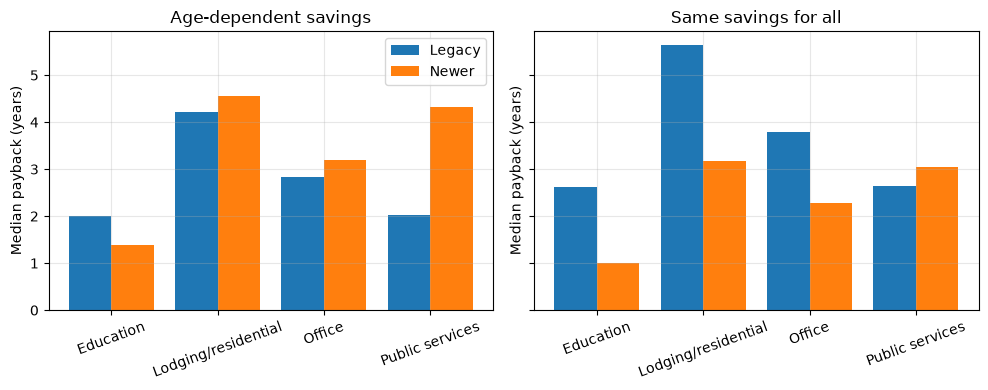

In [22]:
cmp = []
for flag, name in [(True, 'Age-dependent savings'), (False, 'Same savings for all')]:
    d = run_portfolio(age_dependent=flag); d['assumption'] = name; cmp.append(d)
cmp = pd.concat(cmp)
age_tbl = (cmp.groupby(['assumption', 'type', 'legacy'])
              .agg(n=('building_id', 'count'), median_payback=('payback_yrs', 'median'),
                   tCO2_per_1000m2=('tCO2_per_1000m2', 'median')).round(2))
display(age_tbl)

verdict = []
for a, g_ in cmp.groupby('assumption'):
    for t, h_ in g_.groupby('type'):
        if h_.legacy.nunique() == 2:
            lp, npay = h_[h_.legacy].payback_yrs.median(), h_[~h_.legacy].payback_yrs.median()
            verdict.append({'assumption': a, 'type': t, 'legacy_payback': round(lp, 2), 'newer_payback': round(npay, 2),
                            'faster_payback': 'legacy' if lp < npay else 'newer'})
verdict = pd.DataFrame(verdict); display(verdict)

if len(verdict):
    pv = verdict.pivot(index='type', columns='assumption', values=['legacy_payback', 'newer_payback'])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, (a, g_) in zip(axes, verdict.groupby('assumption')):
        x = np.arange(len(g_)); ax.bar(x - 0.2, g_.legacy_payback, 0.4, label='Legacy'); ax.bar(x + 0.2, g_.newer_payback, 0.4, label='Newer')
        ax.set_xticks(x); ax.set_xticklabels(g_.type, rotation=20); ax.set_title(a); ax.set_ylabel('Median payback (years)')
    axes[0].legend(); plt.tight_layout(); plt.show()

**Is the legacy-vs-newer difference real?** With 6-10 buildings per group, medians can differ by chance. The table gives a bootstrap 95% interval for the difference in median payback (legacy minus newer) and a Mann-Whitney test; 'clear difference' means the interval excludes zero. The regression (run with and without the age-dependent savings) shows how much of the variation in payback is explained by energy use per m2 and building size, and how much the legacy flag adds. With age-dependent savings the legacy flag mostly reflects the assumption we put in, so the data-only row is the one to read.

In [23]:
from scipy import stats
rng_b = np.random.default_rng(7)
age_rows, d_age = [], run_portfolio()
for t, h_ in d_age.groupby('type'):
    L, N_ = h_[h_.legacy].payback_yrs.clip(upper=50).values, h_[~h_.legacy].payback_yrs.clip(upper=50).values
    if len(L) < 3 or len(N_) < 3: continue
    diffs = [np.median(rng_b.choice(L, len(L))) - np.median(rng_b.choice(N_, len(N_))) for _ in range(5000)]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    age_rows.append({'type': t, 'n_legacy': len(L), 'n_newer': len(N_),
                     'median_diff_yrs (legacy - newer)': round(np.median(L) - np.median(N_), 2),
                     'CI_low': round(lo, 2), 'CI_high': round(hi, 2),
                     'MWU_p': round(stats.mannwhitneyu(L, N_, alternative='two-sided').pvalue, 3),
                     'clear difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
age_stats = pd.DataFrame(age_rows); display(age_stats)

def explain(d_):
    ok = np.isfinite(d_.payback_yrs.values) & (d_.payback_yrs.values > 0)
    y = np.log(d_.payback_yrs.values[ok]); eui_ = np.log((d_.BAU_kWh / d_.sqm).values[ok])
    size_ = np.log(d_.sqm.values[ok]); lg = d_.legacy.values[ok].astype(float)
    def fit(cols):
        X = np.column_stack([np.ones(len(y))] + cols); beta = np.linalg.lstsq(X, y, rcond=None)[0]
        return 1 - (y - X @ beta).var() / y.var(), beta
    r_e, _ = fit([eui_]); r_es, _ = fit([eui_, size_]); r_all, b_all = fit([eui_, size_, lg])
    return r_e, r_es, r_all, b_all[-1]

reg_age = []
for flag, name in [(False, 'Same savings for all (data only)'), (True, 'Age-dependent savings (includes our assumption)')]:
    r_e, r_es, r_all, coef = explain(run_portfolio(age_dependent=flag))
    reg_age.append({'assumption': name, 'R2 energy use per m2': round(r_e, 2), 'R2 + building size': round(r_es, 2),
                    'R2 + legacy flag': round(r_all, 2), 'legacy coefficient': round(coef, 2)})
reg_age = pd.DataFrame(reg_age); display(reg_age)
print('With age-dependent savings the legacy flag picks up the savings assumption built into the simulation, so only the first row shows what the data alone say.')

,type,n_legacy,n_newer,median_diff_yrs (legacy - newer),CI_low,CI_high,MWU_p,clear difference?
0,Education,6,7,0.62,-0.88,2.03,0.836,no
1,Lodging/residential,10,9,-0.32,-5.32,1.10,0.391,no
2,Office,6,7,-0.37,-4.64,1.02,0.534,no
3,Public services,8,9,-2.29,-3.19,0.54,0.200,no


,assumption,R2 energy use per m2,R2 + building size,R2 + legacy flag,legacy coefficient
0,Same savings for all (data only),0.94,0.99,0.99,-0.01
1,Age-dependent savings (includes our assumption),0.73,0.76,0.98,-0.65


With age-dependent savings the legacy flag picks up the savings assumption built into the simulation, so only the first row shows what the data alone say.


## 14. Retrofit-first ranking
Groups (building type x legacy/newer) are ranked by median payback. Tiers are our own thresholds: Tier 1 = payback up to 3 years (retrofit first), Tier 2 = up to 6 years, Tier 3 = longer. The per-building list shows the individual buildings to prioritise.

,group,n,median_payback,NPV_per_m2_Rs,tCO2_per_1000m2,Rs_per_tCO2,tier
0,Education - newer,7,1.38,1326.119995,26.700001,-8985.780273,Tier 1 (first)
1,Education - legacy,6,2.00,966.919983,22.639999,-8215.639648,Tier 1 (first)
2,Public services - legacy,8,2.03,1041.750000,25.200001,-8242.610352,Tier 1 (first)
3,Office - legacy,6,2.84,494.250000,14.980000,-6987.959961,Tier 1 (first)
4,Office - newer,7,3.20,465.200012,15.970000,-6706.439941,Tier 2
5,Lodging/residential - legacy,10,4.22,237.369995,12.620000,-5507.629883,Tier 2
6,Public services - newer,9,4.32,185.389999,11.040000,-5237.709961,Tier 2
7,Lodging/residential - newer,9,4.55,145.089996,10.360000,-4924.700195,Tier 2


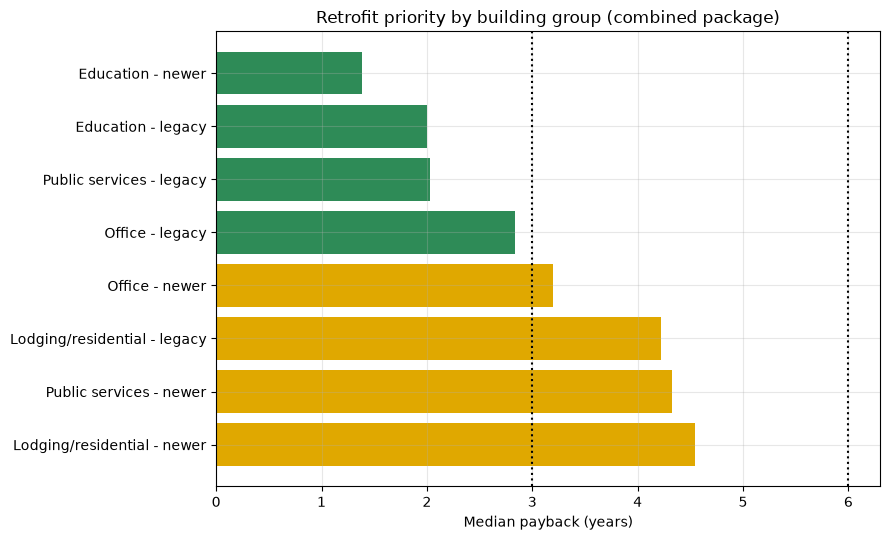

Top 10 individual buildings to retrofit first:


,building_id,type,legacy,sqm,payback_yrs,NPV_Rs,tCO2_avoided_yr
13,Rat_education_Jena,Education,True,3804.4,0.7,13982264.0,235.199997
24,Fox_education_Claude,Education,False,17957.6,0.8,48253440.0,832.000000
17,Cockatoo_education_Sheryl,Education,True,14927.0,0.8,38784676.0,673.500000
21,Cockatoo_education_Tyler,Education,False,19928.2,1.1,34740400.0,651.000000
29,Rat_public_Isabel,Public services,True,1540.0,1.2,3933220.0,73.699997
41,Rat_public_Yessenia,Public services,False,2043.9,1.2,4625103.5,87.400002
19,Cockatoo_education_Janet,Education,False,29946.4,1.3,43514824.0,849.900024
22,Fox_education_Yolande,Education,False,16681.6,1.4,22121868.0,445.399994
48,Cockatoo_lodging_Elvia,Lodging/residential,True,13962.8,1.5,17076228.0,353.000000
37,Fox_public_Denny,Public services,False,4058.1,1.6,5416952.0,113.300003


In [24]:
TIER1, TIER2 = 3, 6
d = run_portfolio()
d['group'] = d.type + ' - ' + np.where(d.legacy, 'legacy', 'newer')
rank = (d.groupby('group')
         .agg(n=('building_id', 'count'), median_payback=('payback_yrs', 'median'),
              NPV_per_m2_Rs=('NPV_Rs', lambda x: (x / d.loc[x.index, 'sqm']).median()),
              tCO2_per_1000m2=('tCO2_per_1000m2', 'median'), Rs_per_tCO2=('Rs_per_tCO2', 'median'))
         .sort_values('median_payback').reset_index())
rank['tier'] = np.where(rank.median_payback <= TIER1, 'Tier 1 (first)', np.where(rank.median_payback <= TIER2, 'Tier 2', 'Tier 3'))
display(rank.round(2))

colors = rank.tier.map({'Tier 1 (first)': '#2E8B57', 'Tier 2': '#E0A800', 'Tier 3': '#C0392B'})
plt.figure(figsize=(9, 0.5 * len(rank) + 1.5))
plt.barh(rank.group[::-1], rank.median_payback[::-1], color=colors[::-1])
plt.axvline(TIER1, color='k', ls=':'); plt.axvline(TIER2, color='k', ls=':')
plt.xlabel('Median payback (years)'); plt.title('Retrofit priority by building group (combined package)'); plt.tight_layout(); plt.show()

print('Top 10 individual buildings to retrofit first:')
d.sort_values('payback_yrs')[['building_id', 'type', 'legacy', 'sqm', 'payback_yrs', 'NPV_Rs', 'tCO2_avoided_yr']].head(10).round(1)

## 15. Regional comparison
The same buildings and the same overlay are evaluated under different electricity grids and prices. Capex is held at the same rupee value in every region, which ignores local labour and equipment cost differences. USD to INR is an assumption.

| Region | Emission factor | Tariff | Source |
|---|---|---|---|
| India | 0.710 kg/kWh | Rs 8/kWh | CEA v21 (FY2024-25); state commercial tariffs |
| India, higher-carbon year | 0.79 kg/kWh | Rs 8/kWh | CEA FY2019-20 |
| United States | 0.394 kg/kWh | 13 cents/kWh | US EPA GHG Equivalencies Calculator (eGRID2022 national output rate, including line losses); EIA commercial price (about 12.75 cents in 2024, about 13-14 cents in 2026) |

,region,tariff_Rs_per_kWh,EF_kg_per_kWh,median_payback_yrs,total_tCO2_avoided_yr,median_Rs_per_tCO2
0,India (CEA FY2024-25),8.0,0.71,3.23,10855.580078,-6537.439941
1,India (CEA FY2019-20 grid),8.0,0.79,3.23,12078.740234,-5875.419922
2,"United States (eGRID, EIA)",11.4,0.39,2.15,6024.080078,-20511.630859


Group priority order (fastest payback first) by region:
  India (CEA FY2024-25): ['Education - newer', 'Education - legacy', 'Public services - legacy', 'Office - legacy', 'Office - newer', 'Lodging/residential - legacy', 'Public services - newer', 'Lodging/residential - newer']
  India (CEA FY2019-20 grid): ['Education - newer', 'Education - legacy', 'Public services - legacy', 'Office - legacy', 'Office - newer', 'Lodging/residential - legacy', 'Public services - newer', 'Lodging/residential - newer']
  United States (eGRID, EIA): ['Education - newer', 'Education - legacy', 'Public services - legacy', 'Office - legacy', 'Office - newer', 'Lodging/residential - legacy', 'Public services - newer', 'Lodging/residential - newer']


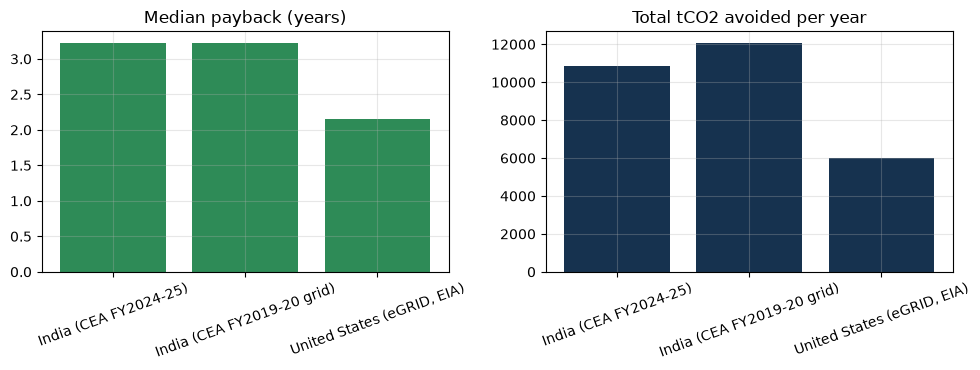

In [25]:
USD_INR = 88   # assumption - update to the current rate
REGIONS = {'India (CEA FY2024-25)': dict(ef=0.710, tariff=8.0),
           'India (CEA FY2019-20 grid)': dict(ef=0.79, tariff=8.0),
           'United States (eGRID, EIA)': dict(ef=0.394, tariff=0.13 * USD_INR)}
reg_rows, reg_rank = [], {}
for name, kw in REGIONS.items():
    d_ = run_portfolio(**kw)
    reg_rows.append({'region': name, 'tariff_Rs_per_kWh': round(kw['tariff'], 1), 'EF_kg_per_kWh': kw['ef'],
                     'median_payback_yrs': d_.payback_yrs.median(), 'total_tCO2_avoided_yr': d_.tCO2_avoided_yr.sum(),
                     'median_Rs_per_tCO2': d_.Rs_per_tCO2.median()})
    d_['group'] = d_.type + ' - ' + np.where(d_.legacy, 'legacy', 'newer')
    reg_rank[name] = d_.groupby('group').payback_yrs.median().sort_values().index.tolist()
reg = pd.DataFrame(reg_rows); display(reg.round(2))
print('Group priority order (fastest payback first) by region:')
for k, v in reg_rank.items(): print(f'  {k}: {v}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].bar(reg.region, reg.median_payback_yrs, color='#2E8B57'); ax[0].set_title('Median payback (years)')
ax[1].bar(reg.region, reg.total_tCO2_avoided_yr, color='#16324F'); ax[1].set_title('Total tCO2 avoided per year')
for a in ax: a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## 16. Headline results
The cell below prints the key numbers from the sections above, so they can be copied into the report and slides.

In [26]:
d = run_portfolio()
top_pay = sens.sort_values('pay_swing', ascending=False).input.iloc[0]
top_co2 = sens.sort_values('co2_swing', ascending=False).input.iloc[0]
print(f"Buildings analysed: {len(d)} of {len(sel)} sampled (baseline CV(RMSE) < 30%); types: {sorted(d.type.unique())}")
print(f"Median payback (combined package): {d.payback_yrs.median():.1f} years; share paying back within 5 years: {(d.payback_yrs <= 5).mean():.0%}")
print(f"Total CO2 avoided: {d.tCO2_avoided_yr.sum():,.0f} t/yr; median {d.tCO2_per_1000m2.median():.1f} t/yr per 1000 m2")
print(f"Median cost per tonne abated: Rs {d.Rs_per_tCO2.median():,.0f} per tCO2 (negative = saves money)")
print(f"Monte Carlo: median payback P5/P50/P95 = {np.percentile(med_pay,5):.1f} / {np.percentile(med_pay,50):.1f} / {np.percentile(med_pay,95):.1f} years")
print(f"Most influential input on payback: {top_pay}; on carbon: {top_co2}")
print('Tier 1 groups:', rank[rank.tier == 'Tier 1 (first)'].group.tolist() or 'none')
for a, g_ in verdict.groupby('assumption'):
    print(f"Legacy vs newer ({a}):", dict(zip(g_.type, g_.faster_payback)))
print('Legacy vs newer, clear difference (bootstrap CI excludes 0):', dict(zip(age_stats.type, age_stats['clear difference?'])))
_r = reg_age.iloc[0]
print(f"Payback variation explained by energy use per m2 and size (data only): {_r['R2 + building size']:.0%}; adding the legacy flag: {_r['R2 + legacy flag']:.0%}")

Buildings analysed: 62 of 80 sampled (baseline CV(RMSE) < 30%); types: ['Education', 'Lodging/residential', 'Office', 'Public services']
Median payback (combined package): 3.2 years; share paying back within 5 years: 82%
Total CO2 avoided: 10,856 t/yr; median 13.9 t/yr per 1000 m2
Median cost per tonne abated: Rs -6,537 per tCO2 (negative = saves money)
Monte Carlo: median payback P5/P50/P95 = 1.8 / 3.1 / 5.7 years
Most influential input on payback: Capex (0.5x-2x); on carbon: Fault-detection savings (5%-16%)
Tier 1 groups: ['Education - newer', 'Education - legacy', 'Public services - legacy', 'Office - legacy']
Legacy vs newer (Age-dependent savings): {'Education': 'newer', 'Lodging/residential': 'legacy', 'Office': 'legacy', 'Public services': 'legacy'}
Legacy vs newer (Same savings for all): {'Education': 'newer', 'Lodging/residential': 'newer', 'Office': 'newer', 'Public services': 'legacy'}
Legacy vs newer, clear difference (bootstrap CI excludes 0): {'Education': 'no', 'Lodging/

## References
1. Miller, C. et al. (2020). The Building Data Genome Project 2, energy meter data from the ASHRAE Great Energy Predictor III competition. *Scientific Data*, 7, 368.
2. Chen, T. & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD*.
3. Williams, A., Atkinson, B., Garbesi, K., Page, E. & Rubinstein, F. (2012). Lighting controls in commercial buildings. *LEUKOS*, 8(3). doi:10.1582/LEUKOS.2012.08.03.001
4. Mills, E. (2011). Building commissioning: a golden opportunity for reducing energy costs and greenhouse-gas emissions in the United States. *Energy Efficiency* (2011). doi:10.1007/s12053-011-9116-8
5. Khabbazi, A. J., Pergantis, E. N., et al. (2025). Lessons learned from field demonstrations of model predictive control and reinforcement learning for residential and commercial HVAC: a review. arXiv:2503.05022.
6. Mariano-Hernandez, D. et al. (2021). A review of strategies for building energy management system. *Journal of Building Engineering*, 33, 101692.
7. Agarwal, Y. et al. (2010). Occupancy-driven energy management for smart building automation. *BuildSys*.
8. Katipamula, S. & Brambley, M. (2005). Methods for fault detection, diagnostics, and prognostics for building systems. *HVAC&R Research*, 11(1-2).
9. Central Electricity Authority, India. CO2 Baseline Database for the Indian Power Sector, versions 20.0 (Dec 2024) and 21.0 (Dec 2025).
10. Central Electricity Authority, India. Electricity Tariff & Duty and Average Rates of Electricity Supply in India (annual compilation).
11. Bureau of Energy Efficiency / TERI. Existing Commercial Building Retrofit Guidelines (commercial end-use shares: HVAC about 55%, lighting about 23%).
12. US EPA. Greenhouse Gas Equivalencies Calculator, calculations and references (eGRID national output emission rate).
13. US EIA. Electric Power Monthly and EIA-861 average retail price of electricity, commercial sector.
14. ASHRAE Guideline 14: Measurement of Energy, Demand, and Water Savings (CV(RMSE) acceptance criterion).

Page numbers are omitted where not confirmed; verify exact titles, volumes and pages against the original sources before submission. The age-dependent savings split, the capex and opex figures, and the tier thresholds are the team's own assumptions.